# ComputAge_Bench_analysis

**MAIN Research Question:** can the age of a healthy person be predicted from the methylation of their blood, 
**Secondary Research Question:** does a small multilayer perceptron(MLP) in PyTorch beat the classic elastic net?

**How to run (Visual Studio Code, graphical interface - note to self, this section, and the ones below, to be added to the README leter):** 
- [ ] Open the repository folder in Visual Studio Code (Explorer panel on the left).
- [ ] Choose the `.venv` environment as the kernel (top right of the notebook).
- [ ] Run the optional installation cell below once, then choose **Run All**.

The notebook writes its results into the folder `results/`.

**Data:** ComputAge Bench, https://huggingface.co/datasets/computage/computage_bench. The dataset card gives the license as Creative Commons Attribution-ShareAlike 4.0. The whole repository is 38.6 gigabytes, and some study files are over one gigabyte (the file listing shows 1.2 gigabytes for GSE56105), so the notebook checks the size of a file before it downloads it. How to cite the data is left for the README.

**Folders (all created by the notebook, in addition to the data downloaded from it)**
- `metadata/` holds the small metadata table.
- `data/` holds the one downloaded study file (inside `data/train/`).
- `results/` holds the tables, figures and records that the notebook writes.

**Key terms**
- **Methylation site:** one position on the deoxyribonucleic acid where a chemical mark can be measured.
- **Beta value:** the fraction of molecules that carry the mark at a site, from 0 to 1.
- **Elastic net:** a linear model with two penalties that set most site weights to exactly zero.
- **Multilayer perceptron:** a small neural network made of fully connected layers.
- **Leakage:** information from the test samples reaching training or site selection. It makes results look better than they are.
- **Median absolute error:** the middle value of the list of absolute differences between predicted and real age, in years.

**Known data problems to keep in mind**
- Some studies in the collection hold sorted cell types (for example monocytes) and not whole blood. The notebook only accepts a study with one single cell type and prints it.
- Studies differ in array platform, laboratory and population, so a result from one study may not transfer to another.
- The metadata columns listed on the dataset card contain no column that names the person. The notebook assumes one sample per person. This is not tested here.

## Step 0: install the packages

Run this once. It installs the exact versions listed in `requirements.txt`, which sits next to this notebook. Restart the kernel afterwards if Visual Studio Code asks.

In [ ]:
# Step 0 - install the packages from requirements.txt (run once)
# %pip install -r requirements.txt

  Using cached torch-2.15.0-cp314-cp314-win_amd64.whl.metadata (36 kB)
  Using cached numpy-2.5.3-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached pandas-3.0.5-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached pyarrow-26.0.1-cp314-cp314-win_amd64.whl.metadata (3.0 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached filelock-4.2.10-py3-none-any.whl.metadata (2.3 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 1: imports, settings and package versions

Every import of the notebook is in the first cell. The second cell holds the settings; the defaults work. The versions are printed as plain lines so that you can copy them into the README.

**Expected output:** the Python version, the operating system, one line per package, and the computing device.

In [2]:
# Step 1.1 - every import of the notebook, in one place
import copy
import datetime
import importlib.metadata
import json
import os
import platform
import random

import huggingface_hub
import matplotlib.pyplot as pyplot
import numpy
import pandas
import sklearn.linear_model
import sklearn.model_selection
import sklearn.preprocessing
import torch

In [ ]:
# Step 1.2 - settings
DATA_FOLDER = "data"               # the study file is stored in data/train/ (its path in the repository)
METADATA_FOLDER = "metadata"       # the metadata table
RESULTS_FOLDER = "results"
for folder_name in [DATA_FOLDER, METADATA_FOLDER, RESULTS_FOLDER]:
    os.makedirs(folder_name, exist_ok=True)   # create the folders before they are used

REPOSITORY_NAME = "computage/computage_bench"
METADATA_FILE = "computage_train_meta.tsv"
STUDY_FILE_PATTERN = "data/train/computage_train_data_{study}.parquet"

STUDY_IDENTIFIER = None            # None = choose automatically. Or write one, for example "GSE49064"
MINIMUM_SAMPLES = 100              # rule for the automatic choice
MAXIMUM_SAMPLES = 600
MAXIMUM_FILE_MEGABYTES = 500       # studies with a bigger file are skipped
MAXIMUM_SITES_TO_KEEP = None       # for example 100000 if the computer runs out of memory
NUMBER_OF_SITES = 2000             # sites kept after selection on the training samples
SEEDS = [0, 1, 42]                 # every seed gives a different split and a different network start
RUN_LEAKAGE_DEMONSTRATION = True   # Step 10.3, a deliberate mistake shown on purpose
WRITE_REQUIREMENTS_FILE = False    # True = write requirements.txt from the versions printed below

PACKAGES = ["torch", "numpy", "pandas", "scikit-learn", "matplotlib", "pyarrow", "huggingface_hub", "ipykernel"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python:", platform.python_version())
print("Operating system:", platform.platform())
for package_name in PACKAGES:
    print(package_name + ":", importlib.metadata.version(package_name))
print("PyTorch version with its build (processor only or graphics card):", torch.__version__)
print("Computing on:", device)

Python: 3.14.7
Operating system: Windows-11-10.0.26300-SP0
torch: 2.15.0
numpy: 2.5.3
pandas: 3.0.5
scikit-learn: 1.9.1
matplotlib: 3.11.2
pyarrow: 26.0.1
huggingface_hub: 2.4.0
ipykernel: 7.4.0
PyTorch version with its build (processor only or graphics card): 2.15.0+cpu
Computing on: cpu


In [4]:
# Step 1.3 - optional: write requirements.txt with the versions printed above
if WRITE_REQUIREMENTS_FILE:
    with open("requirements.txt", "w", encoding="utf-8") as requirements_file:
        for package_name in PACKAGES:
            requirements_file.write(package_name + "==" + importlib.metadata.version(package_name) + "\n")
    print("requirements.txt written with the versions printed above.")
else:
    print("requirements.txt was not changed (set WRITE_REQUIREMENTS_FILE = True to write it).")

requirements.txt was not changed (set WRITE_REQUIREMENTS_FILE = True to write it).


## Step 2: get the data

**What and why:** we first ask the repository which files it has (this downloads nothing large) and check that the files we need exist. Then we download the small metadata table and let the notebook choose one study.

**Choice rule for the study:** blood tissue, one single cell type, between 100 and 600 samples, a file no bigger than the size limit, and the widest possible age range. A wide age range gives a clear signal, and a few hundred samples keep the file small.

**Labels, taken from the dataset card and its file listing:**
- The metadata table is indexed by sample (`SampleID`). Its columns are `DatasetID` (the study), `PlatformID` (the array platform), `Tissue`, `CellType`, `Gender`, `Age`, `Condition` and `Class`.
- `Age` is the age in years. It is the value we predict.
- `HC` stands for healthy control. The card says the training folder holds healthy controls only. The notebook checks this.
- A study file holds methylation beta values, with the sites in the rows and the samples in the columns. The notebook checks this orientation too.

In [5]:
# Step 2.1 - ask the repository for its file names (nothing large is downloaded)
repository_files = huggingface_hub.list_repo_files(REPOSITORY_NAME, repo_type="dataset")
study_files = [name for name in repository_files if name.startswith("data/train/") and name.endswith(".parquet")]
print("Files listed in the repository:", len(repository_files))
print("Study files in the training folder:", len(study_files))

if METADATA_FILE not in repository_files:
    raise FileNotFoundError(METADATA_FILE + " is not in the repository. Check the file name on the dataset page.")
print("Metadata file found:", METADATA_FILE)

Files listed in the repository: 116
Study files in the training folder: 46
Metadata file found: computage_train_meta.tsv


In [6]:
# Step 2.2 - download and read the metadata table (a few hundred kilobytes)
metadata_path = huggingface_hub.hf_hub_download(
    repo_id=REPOSITORY_NAME,
    filename=METADATA_FILE,
    repo_type="dataset",
    local_dir=METADATA_FOLDER,
)
metadata = pandas.read_csv(metadata_path, sep="\t", index_col=0)

EXPECTED_COLUMNS = ["DatasetID", "PlatformID", "Tissue", "CellType", "Gender", "Age", "Condition", "Class"]
missing_columns = [column for column in EXPECTED_COLUMNS if column not in metadata.columns]

print("Samples (rows):", len(metadata))
print("Studies:", metadata["DatasetID"].nunique())
print("Name of the row index:", metadata.index.name)
print("Columns:", list(metadata.columns))
print("Expected columns missing:", missing_columns if missing_columns else "none")
if missing_columns:
    raise KeyError("The metadata table differs from the dataset card. Missing columns: " + str(missing_columns))

print("Tissue values:", metadata["Tissue"].value_counts().to_dict())
print("Condition values:", metadata["Condition"].value_counts().to_dict())
print("Only healthy controls (the dataset card says so for the training folder):", set(metadata["Condition"].unique()) == {"HC"})
print("Age in years: youngest", float(metadata["Age"].min()), "| oldest", float(metadata["Age"].max()), "| missing", int(metadata["Age"].isna().sum()))

c:\Users\evapa\Documents\DNA_methylation_aging\Predicting_age_from_DNA_methylation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Samples (rows): 7419
Studies: 46
Name of the row index: SampleID
Columns: ['DatasetID', 'PlatformID', 'Tissue', 'CellType', 'Gender', 'Age', 'Condition', 'Class']
Expected columns missing: none
Tissue values: {'Blood': 7419}
Condition values: {'HC': 7419}
Only healthy controls (the dataset card says so for the training folder): True
Age in years: youngest 0.02 | oldest 891.0 | missing 0


In [7]:
# Step 2.3 - summarise every study and choose one
study_summary = metadata.groupby("DatasetID").agg(
    samples=("Age", "size"),
    youngest=("Age", "min"),
    oldest=("Age", "max"),
    tissue=("Tissue", "first"),
    tissue_values=("Tissue", "nunique"),
    cell_types=("CellType", "nunique"),
    platform=("PlatformID", "first"),
)
study_summary["age_range"] = study_summary["oldest"] - study_summary["youngest"]
study_summary["has_file"] = [STUDY_FILE_PATTERN.format(study=name) in repository_files for name in study_summary.index]


# HELPER FUNCTION - size of one study file in megabytes, asked from the repository (no download)
def file_size_in_megabytes(study):
    information = huggingface_hub.get_paths_info(
        REPOSITORY_NAME, [STUDY_FILE_PATTERN.format(study=study)], repo_type="dataset"
    )
    return information[0].size / 1e6


candidates = study_summary[
    (study_summary["tissue"] == "Blood")
    & (study_summary["tissue_values"] == 1)
    & (study_summary["cell_types"] == 1)
    & (study_summary["samples"] >= MINIMUM_SAMPLES)
    & (study_summary["samples"] <= MAXIMUM_SAMPLES)
    & (study_summary["has_file"])
].sort_values("age_range", ascending=False)

print("Studies in total:", len(study_summary))
print("Studies that fit the choice rule (before the size limit):", len(candidates))

if STUDY_IDENTIFIER is None:
    for candidate in candidates.index:
        candidate_size = file_size_in_megabytes(candidate)
        print("Candidate", candidate, "| samples", int(candidates.loc[candidate, "samples"]),
              "| age range", float(candidates.loc[candidate, "age_range"]), "| file megabytes", round(candidate_size, 1))
        if candidate_size <= MAXIMUM_FILE_MEGABYTES:
            STUDY_IDENTIFIER = candidate
            break
    if STUDY_IDENTIFIER is None:
        raise RuntimeError("No candidate has a file of at most " + str(MAXIMUM_FILE_MEGABYTES)
                           + " megabytes. Raise MAXIMUM_FILE_MEGABYTES in Step 1.2 or write a study name there.")
else:
    if STUDY_IDENTIFIER not in study_summary.index or not study_summary.loc[STUDY_IDENTIFIER, "has_file"]:
        raise KeyError(STUDY_IDENTIFIER + " has no study file in the training folder.")
    chosen_size = file_size_in_megabytes(STUDY_IDENTIFIER)
    print("Study chosen by hand:", STUDY_IDENTIFIER, "| file megabytes", round(chosen_size, 1))
    if chosen_size > MAXIMUM_FILE_MEGABYTES:
        print("Warning: the file is bigger than MAXIMUM_FILE_MEGABYTES. The download may be slow and need much memory.")

study_row = study_summary.loc[STUDY_IDENTIFIER]
study_cell_type = metadata.loc[metadata["DatasetID"] == STUDY_IDENTIFIER, "CellType"].iloc[0]
print("Chosen study:", STUDY_IDENTIFIER)
print("Samples:", int(study_row["samples"]), "| platform:", study_row["platform"], "| tissue:", study_row["tissue"], "| cell type:", study_cell_type)
print("Age in years: youngest", float(study_row["youngest"]), "| oldest", float(study_row["oldest"]))

Studies in total: 46
Studies that fit the choice rule (before the size limit): 15
Candidate GSE80417 | samples 305 | age range 873.0 | file megabytes 592.8
Candidate GSE234461 | samples 245 | age range 89.96 | file megabytes 857.0
Candidate GSE179325 | samples 101 | age range 81.0 | file megabytes 314.5
Chosen study: GSE179325
Samples: 101 | platform: GPL21145 | tissue: Blood | cell type: Whole blood
Age in years: youngest 19.0 | oldest 100.0


In [8]:
# Step 2.4 - download the one study file and bring it into the shape samples x sites
study_file = STUDY_FILE_PATTERN.format(study=STUDY_IDENTIFIER)
study_path = huggingface_hub.hf_hub_download(
    repo_id=REPOSITORY_NAME,
    filename=study_file,
    repo_type="dataset",
    local_dir=".", 
)
table_from_file = pandas.read_parquet(study_path)

# The dataset card says: sites in the rows, samples in the columns. We check it and do not just trust it.
sample_names_in_columns = int(table_from_file.columns.isin(metadata.index).sum())
sample_names_in_rows = int(table_from_file.index.isin(metadata.index).sum())
print("Sample names found in the columns:", sample_names_in_columns, "| in the rows:", sample_names_in_rows)

if sample_names_in_columns > sample_names_in_rows:
    print("Sites are in the rows, as the card says. The table is turned around (transposed).")
    methylation = table_from_file.T
else:
    print("Samples are already in the rows. The table is used as it is.")
    methylation = table_from_file

if MAXIMUM_SITES_TO_KEEP is not None and methylation.shape[1] > MAXIMUM_SITES_TO_KEEP:
    methylation = methylation.sample(n=MAXIMUM_SITES_TO_KEEP, axis=1, random_state=0)
    print("A random subset of sites was kept:", MAXIMUM_SITES_TO_KEEP)

methylation = methylation.astype("float32")      # rows = samples, columns = sites
del table_from_file

print("Table shape (samples, sites):", methylation.shape)
print("Smallest and largest value:", float(numpy.nanmin(methylation.to_numpy())), float(numpy.nanmax(methylation.to_numpy())))

Sample names found in the columns: 101 | in the rows: 0
Sites are in the rows, as the card says. The table is turned around (transposed).
Table shape (samples, sites): (101, 768067)
Smallest and largest value: 0.0 0.9961437582969666


## Step 3: data checks

**What and why:** these are the lean checks that matter. Each result is recorded, and nothing is changed silently.

**Checklist**
- [ ] Every sample has an age. Samples without an age cannot be used and are removed.
- [ ] Sample names are unique.
- [ ] Values lie between 0 and 1.
- [ ] How many values are missing. Missing values are filled later, using training samples only.
- [ ] No sample is a copy of another one (checked on the first 20,000 sites).
- [ ] Which person each sample belongs to, so that the split in Step 4 can be done by person.

In [9]:
# Step 3.1 - match the samples of the file with their ages
study_metadata = metadata.loc[metadata["DatasetID"] == STUDY_IDENTIFIER]
shared_sample_names = [name for name in methylation.index if name in study_metadata.index]
print("Samples in the data file:", len(methylation), "| with metadata:", len(shared_sample_names))
print("Samples in the metadata but not in the data file:", len(study_metadata) - len(shared_sample_names))

methylation = methylation.loc[shared_sample_names]
ages = study_metadata.loc[shared_sample_names, "Age"].astype("float32")

samples_with_age = ages.index[ages.notna()]
print("Samples without an age (removed):", len(ages) - len(samples_with_age))
methylation = methylation.loc[samples_with_age]
ages = ages.loc[samples_with_age]

print("Usable samples:", len(ages))
print("Age in years: youngest", float(ages.min()), "| oldest", float(ages.max()), "| median", float(ages.median()))

Samples in the data file: 101 | with metadata: 101
Samples in the metadata but not in the data file: 0
Samples without an age (removed): 0
Usable samples: 101
Age in years: youngest 19.0 | oldest 100.0 | median 70.0


In [10]:
# Step 3.2 - checks on the values, the names and the people
data_checks = {}
data_checks["usable_samples"] = int(len(ages))
data_checks["sample_names_unique"] = bool(methylation.index.is_unique)

value_array = methylation.to_numpy()
data_checks["values_below_zero"] = int((value_array < 0).sum())
data_checks["values_above_one"] = int((value_array > 1).sum())
data_checks["fraction_missing"] = float(methylation.isna().mean().mean())
data_checks["samples_with_every_value_missing"] = int(methylation.isna().all(axis=1).sum())
data_checks["copied_samples_in_first_20000_sites"] = int(methylation.iloc[:, :20000].duplicated().sum())

print("Sample names unique:", data_checks["sample_names_unique"])
print("Values below 0:", data_checks["values_below_zero"], "| values above 1:", data_checks["values_above_one"])
print("Fraction of missing values overall:", round(data_checks["fraction_missing"], 4))
print("Samples with every value missing:", data_checks["samples_with_every_value_missing"])
print("Samples that copy another sample (first 20,000 sites):", data_checks["copied_samples_in_first_20000_sites"])

# Which person does each sample belong to? Use a column that names the person if one exists.
PERSON_COLUMN_NAMES = ["subject", "patient", "individual", "donor", "person"]
person_columns = [column for column in metadata.columns if column.lower() in PERSON_COLUMN_NAMES]
if person_columns:
    person_of_sample = study_metadata.loc[methylation.index, person_columns[0]].astype(str)
    print("People are taken from the column:", person_columns[0])
else:
    person_of_sample = pandas.Series(list(methylation.index), index=methylation.index)
    print("No column names the person. One sample per person is assumed (not tested here).")
data_checks["people"] = int(person_of_sample.nunique())
data_checks["most_samples_of_one_person"] = int(person_of_sample.value_counts().max())
print("People:", data_checks["people"], "| most samples of one person:", data_checks["most_samples_of_one_person"])

Sample names unique: True
Values below 0: 0 | values above 1: 0
Fraction of missing values overall: 0.0
Samples with every value missing: 0
Samples that copy another sample (first 20,000 sites): 0
No column names the person. One sample per person is assumed (not tested here).
People: 101 | most samples of one person: 1


Before any model, look at the table with your own eyes.
Standard checks for a methylation dataset

*Possible with this table (Steps 3.1 to 3.4):*
- [ ] Beta values lie between 0 and 1.
- [ ] Missing values, counted per sample and per site.
- [ ] The shape of the beta value distribution. It usually has two groups of values, one near 0 and one near 1.
- [ ] Sample outliers: a sample whose mean beta value or missing fraction lies far from all the others.
- [ ] Unique sample names, no copied samples, every age present and plausible.
- [ ] Balance of the metadata: gender, age range, one platform, one cell type.

*Not possible here, because they need raw measurements or the annotation file of the array, which this dataset file does not contain. Treat them as limits:*
- Detection p-values, and removing samples or sites that failed to measure.
- Normalisation and correction for batch effects. What the dataset authors did is not verified here. Check the dataset card and the paper before you write it in the README.
- Removing sites that are known to be unreliable (sites that bind to several places on the genome, or that overlap common genetic variants), and often the sites on the sex chromosomes. This needs the annotation file of the array.
- Comparing the recorded gender with the gender predicted from the sex chromosome sites.
- Estimating the mix of blood cell types in each sample. It changes with age and influences methylation.

# Step 3.3 - the top and the bottom of the table
print("Shape (samples, sites):", methylation.shape)
print("Data type of the values:", methylation.dtypes.iloc[0])
print("Memory used by the table in megabytes:", round(methylation.to_numpy().nbytes / 1e6, 1))
print("First five site names:", list(methylation.columns[:5]))
print("Last five site names:", list(methylation.columns[-5:]))
print()
print("First five samples, first five sites:")
print(methylation.iloc[:5, :5].round(3).to_string())
print()
print("Last five samples, last five sites:")
print(methylation.iloc[-5:, -5:].round(3).to_string())
print()
print("Metadata of the first five samples:")
print(study_metadata.head().to_string())
print()
print("Metadata of the last five samples:")
print(study_metadata.tail().to_string())

Gender values in this study: {'F': 54, 'M': 47} (the meaning of the letters is on the dataset card)
Platform: ['GPL21145'] | cell type: ['Whole blood']
Missing fraction per sample: smallest 0.0 | median 0.0 | largest 0.0
Sites with no missing value: 768067 of 768067
Sites with more than 10 percent missing: 0
Mean beta value per sample (20,000 random sites): smallest 0.546 | median 0.57 | largest 0.586
The three samples with the lowest mean beta value: {'GSM5414749': 0.546, 'GSM5414556': 0.55, 'GSM5414634': 0.55}
The three samples with the highest mean beta value: {'GSM5414514': 0.586, 'GSM5414503': 0.582, 'GSM5414446': 0.579}


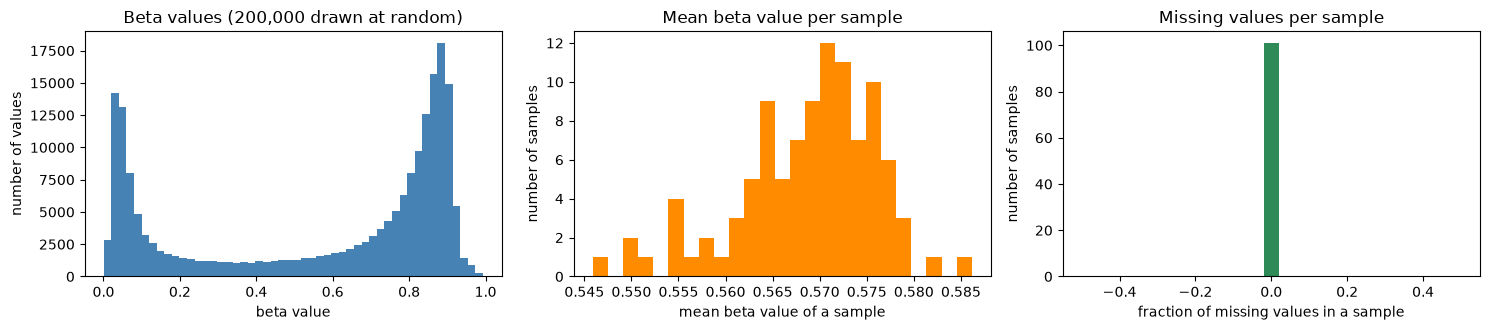

In [11]:
# Step 3.4 - summaries and a picture of the values (nothing here is used to choose or change anything)
print("Gender values in this study:", study_metadata["Gender"].value_counts().to_dict(), "(the meaning of the letters is on the dataset card)")
print("Platform:", study_metadata["PlatformID"].unique().tolist(), "| cell type:", study_metadata["CellType"].unique().tolist())

missing_per_sample = methylation.isna().mean(axis=1)
missing_per_site = methylation.isna().mean(axis=0)
print("Missing fraction per sample: smallest", round(float(missing_per_sample.min()), 4),
      "| median", round(float(missing_per_sample.median()), 4), "| largest", round(float(missing_per_sample.max()), 4))
print("Sites with no missing value:", int((missing_per_site == 0).sum()), "of", methylation.shape[1])
print("Sites with more than 10 percent missing:", int((missing_per_site > 0.10).sum()))

# a random subset of sites keeps this step fast and light on memory
subset_of_sites = methylation.sample(n=min(20000, methylation.shape[1]), axis=1, random_state=0)
mean_beta_per_sample = subset_of_sites.mean(axis=1)
print("Mean beta value per sample (20,000 random sites): smallest", round(float(mean_beta_per_sample.min()), 3),
      "| median", round(float(mean_beta_per_sample.median()), 3), "| largest", round(float(mean_beta_per_sample.max()), 3))
print("The three samples with the lowest mean beta value:", {name: round(float(value), 3) for name, value in mean_beta_per_sample.nsmallest(3).items()})
print("The three samples with the highest mean beta value:", {name: round(float(value), 3) for name, value in mean_beta_per_sample.nlargest(3).items()})

# 200,000 values drawn at random from the whole table
value_array = methylation.to_numpy()
random_generator = numpy.random.default_rng(0)
drawn_values = value_array[random_generator.integers(0, value_array.shape[0], 200000),
                           random_generator.integers(0, value_array.shape[1], 200000)]
drawn_values = drawn_values[~numpy.isnan(drawn_values)]

figure, axes = pyplot.subplots(1, 3, figsize=(15, 3.4))
axes[0].hist(drawn_values, bins=50, color="steelblue")
axes[0].set_xlabel("beta value")
axes[0].set_ylabel("number of values")
axes[0].set_title("Beta values (200,000 drawn at random)")
axes[1].hist(mean_beta_per_sample, bins=25, color="darkorange")
axes[1].set_xlabel("mean beta value of a sample")
axes[1].set_ylabel("number of samples")
axes[1].set_title("Mean beta value per sample")
axes[2].hist(missing_per_sample, bins=25, color="seagreen")
axes[2].set_xlabel("fraction of missing values in a sample")
axes[2].set_ylabel("number of samples")
axes[2].set_title("Missing values per sample")
pyplot.tight_layout()
pyplot.savefig(os.path.join(RESULTS_FOLDER, "data_overview.png"), dpi=120)
pyplot.show()

## Step 4: split by person, prepare the features, and build the loaders

**The most important rule of this project:** every step that *learns anything from the data* (filling gaps, choosing sites, scaling) uses the **training samples only**. If the test samples influence these steps, the test score is too good to be true. This is **leakage**.

**Pipeline order**
1. Split the people into training, validation and test (70, 15 and 15 percent). A person is never in two splits.
2. Drop sites with more than 10 percent missing values in the training samples.
3. Fill the remaining gaps with the training median of each site.
4. Choose the sites most correlated with age, using the training samples only.
5. Scale every site to mean 0 and spread 1, using the training samples only.

The whole pipeline is one function, so exactly the same steps can be repeated for other seeds.

**Are the data ready for the split?** Yes, once the checks of Step 3 are clean. The values already come as beta values, so nothing has to be converted. What the dataset authors did before (normalisation, removal of unreliable sites) is not verified here, and the README should say so. Before the split the notebook only does things that learn nothing from the data: it removes samples without an age, turns the table the right way round, and groups the samples by person. Everything that does learn from the data (gaps, choice of sites, scaling) comes after the split, on purpose.

In [12]:
# Step 4.1 - helpers: split by person, and find the sites most related to age
def split_names_by_person(split_seed):    # HELPER FUNCTION
    people = sorted(person_of_sample.unique())
    training_people, remaining_people = sklearn.model_selection.train_test_split(people, test_size=0.30, random_state=split_seed)
    validation_people, test_people = sklearn.model_selection.train_test_split(remaining_people, test_size=0.50, random_state=split_seed)
    names_by_split = {}
    for split_name, split_people in [("training", training_people), ("validation", validation_people), ("test", test_people)]:
        people_in_split = set(split_people)
        names_by_split[split_name] = [name for name in methylation.index if person_of_sample[name] in people_in_split]
    return names_by_split


def top_correlated_sites(feature_table, ages_in_years, how_many):    # HELPER FUNCTION
    # returns the names of the sites whose values correlate most strongly (up or down) with age
    values = feature_table.to_numpy(dtype="float32")
    centred_values = values - values.mean(axis=0)
    centred_ages = (ages_in_years.to_numpy() - ages_in_years.to_numpy().mean()).astype("float32")
    numerator = centred_values.T @ centred_ages
    denominator = numpy.sqrt((centred_values ** 2).sum(axis=0)) * numpy.sqrt((centred_ages ** 2).sum()) + 1e-12
    correlations = numerator / denominator
    best_positions = numpy.argsort(-numpy.abs(correlations))[:how_many]
    return feature_table.columns[best_positions]

In [ ]:
# Step 4.2 - the whole preparation pipeline
def prepare_data(split_seed, selection_uses="training_only"):    # HELPER FUNCTION
    # selection_uses = "training_only" is correct.
    # selection_uses = "all_samples" is a deliberate mistake, used only in Step 10.3 to show what leakage does.
    names_by_split = split_names_by_person(split_seed)

    training_table = methylation.loc[names_by_split["training"]]
    missing_fraction = training_table.isna().mean()
    kept_sites = missing_fraction[missing_fraction <= 0.10].index           # (2) drop sites with many gaps
    training_medians = training_table[kept_sites].median().to_numpy()
    filled = {}
    for split_name, names in names_by_split.items():                         # (3) fill gaps with the training median
        split_values = methylation.loc[names, kept_sites].to_numpy()
        split_values = numpy.where(numpy.isnan(split_values), training_medians, split_values)    # fast way to fill the gaps
        filled[split_name] = pandas.DataFrame(split_values, index=names, columns=kept_sites)

    if selection_uses == "training_only":                                    # (4) choose the sites
        selected_sites = top_correlated_sites(filled["training"], ages.loc[names_by_split["training"]], NUMBER_OF_SITES)
    else:
        everything = pandas.concat(list(filled.values()))
        selected_sites = top_correlated_sites(everything, ages.loc[everything.index], NUMBER_OF_SITES)

    scaler = sklearn.preprocessing.StandardScaler().fit(filled["training"][selected_sites])    # (5) scale
    data = {"selected_sites": selected_sites, "sites_left_after_gap_filter": len(kept_sites)}
    for split_name, names in names_by_split.items():
        data[split_name + "_features"] = scaler.transform(filled[split_name][selected_sites]).astype("float32")
        data[split_name + "_ages"] = ages.loc[names].to_numpy().astype("float32")
        data[split_name + "_names"] = names
    return data


prepared = prepare_data(split_seed=0)
print("Sites left after the gap filter:", prepared["sites_left_after_gap_filter"])
print("Sites selected:", len(prepared["selected_sites"]))
for split_name in ["training", "validation", "test"]:
    print(split_name, "samples:", len(prepared[split_name + "_ages"]),
          "| median age:", round(float(numpy.median(prepared[split_name + "_ages"])), 1))

people_in_training = set(person_of_sample[prepared["training_names"]])
people_in_validation = set(person_of_sample[prepared["validation_names"]])
people_in_test = set(person_of_sample[prepared["test_names"]])
print("People in more than one split:", len(people_in_training & people_in_validation)
      + len(people_in_training & people_in_test) + len(people_in_validation & people_in_test))
print("Shape of the training features:", prepared["training_features"].shape)

KeyboardInterrupt: 

In [ ]:
# Step 4.3 - tensors and loaders (the network learns from ages scaled to mean 0 and spread 1)
def make_loader(features, targets, shuffle, seed):    # HELPER FUNCTION
    dataset = torch.utils.data.TensorDataset(
        torch.tensor(features, dtype=torch.float32), torch.tensor(targets, dtype=torch.float32)
    )
    generator = torch.Generator().manual_seed(seed)
    return torch.utils.data.DataLoader(dataset, batch_size=32, shuffle=shuffle, generator=generator)


training_age_mean = float(prepared["training_ages"].mean())
training_age_spread = float(prepared["training_ages"].std())
scaled_training_ages = (prepared["training_ages"] - training_age_mean) / training_age_spread
train_loader = make_loader(prepared["training_features"], scaled_training_ages, shuffle=True, seed=0)

one_item_features, one_item_age = train_loader.dataset[0]
print("One item: features", tuple(one_item_features.shape), "| scaled age", round(float(one_item_age), 3))
batch_features, batch_ages = next(iter(train_loader))
print("One batch: features", tuple(batch_features.shape), "| ages", tuple(batch_ages.shape))
print("The validation and test samples are few, so they are predicted in one piece and need no loader.")

## Step 5: a first look at the data

**What and why:** before any model, look at the ages and at a few sites. A wide age range and a visible slope make a prediction possible.

In [ ]:
# Step 5.1 - the first five training samples
for position in range(5):
    print(prepared["training_names"][position], "| age", round(float(prepared["training_ages"][position]), 1),
          "| first five scaled site values", numpy.round(prepared["training_features"][position, :5], 2))

In [ ]:
# Step 5.2 - the ages and the four sites most related to age (training samples only)
figure, axes = pyplot.subplots(1, 5, figsize=(18, 3.2))
axes[0].hist(prepared["training_ages"], bins=25, color="steelblue")
axes[0].set_xlabel("age in years")
axes[0].set_ylabel("number of samples")
axes[0].set_title("Training ages")
training_ages_in_years = ages.loc[prepared["training_names"]]
for position, site_name in enumerate(prepared["selected_sites"][:4]):
    axes[position + 1].scatter(training_ages_in_years, methylation.loc[prepared["training_names"], site_name], s=10)
    axes[position + 1].set_xlabel("age in years")
    axes[position + 1].set_ylabel("beta value")
    axes[position + 1].set_title(site_name)
pyplot.tight_layout()
pyplot.savefig(os.path.join(RESULTS_FOLDER, "first_look.png"), dpi=120)
pyplot.show()

## Step 6: the do-nothing baseline

**Definition of a baseline.** A baseline is the simplest prediction rule that does not use the methylation values at all. It sets the minimum bar that a real model has to clear. Here the rule is to predict one fixed age for every person, calculated from the training ages only: the **mean** age (the number that gives the smallest squared error) or the **median** age (the number that gives the smallest absolute error). The baseline answers one question: how large is the error if the model learns nothing from methylation and only knows the typical age of the group? If a model is not clearly below that error, it has not learned anything useful from the sites. The baseline error is large when the ages are spread widely, so always compare a model with the baseline of the same split. A correlation cannot be calculated for a baseline, because all its predictions are the same number. (In scikit-learn the same rule exists as `DummyRegressor`.)

**What and why:** a model score means nothing without something to compare it with. The baseline predicts the same age for everybody. We compute two: the **mean** training age (the project template) and the **median** training age (the choice of the first guide, and the best constant for the median absolute error). Here they are scored on the **validation** samples only. The test samples stay untouched until Step 9.

**Error measures:** median absolute error (main measure), mean absolute error, and the correlation between predicted and real age. All come from one helper function.

In [ ]:
# Step 6 - error measures and the baselines on the validation samples
def describe_errors(true_ages, predicted_ages):    # HELPER FUNCTION
    differences = predicted_ages - true_ages
    if len(true_ages) > 1 and numpy.max(predicted_ages) > numpy.min(predicted_ages):
        correlation = float(numpy.corrcoef(true_ages, predicted_ages)[0, 1])
    else:
        correlation = float("nan")
    return {
        "median_absolute_error_years": float(numpy.median(numpy.abs(differences))),
        "mean_absolute_error_years": float(numpy.mean(numpy.abs(differences))),
        "correlation": correlation,
    }


validation_ages = prepared["validation_ages"]
mean_age_prediction = numpy.full(len(validation_ages), prepared["training_ages"].mean(), dtype="float32")
median_age_prediction = numpy.full(len(validation_ages), numpy.median(prepared["training_ages"]), dtype="float32")
print("Validation, baseline (always the mean training age): median absolute error",
      round(describe_errors(validation_ages, mean_age_prediction)["median_absolute_error_years"], 2), "years")
print("Validation, baseline (always the median training age): median absolute error",
      round(describe_errors(validation_ages, median_age_prediction)["median_absolute_error_years"], 2), "years")

### Study notes for Step 7: the network in theory

*Textbook material, so no references are added. If you cite any of it in the README, check a source first.*

**1. What kind of problem.** Regression: learn a rule that turns 2,000 numbers (one per site) into one number (the age). It is *supervised*, because every training sample comes with its true age.

**2. One layer.** A fully connected layer (`torch.nn.Linear`) gives, for each of its output numbers, a weighted sum of all its input numbers plus an offset called the bias. A layer with `n` inputs and `m` outputs holds `m x n` weights and `m` biases. In PyTorch the table of weights has the shape `(m, n)`.

| Layer | Inputs | Outputs | Weights | Biases | Learnable numbers |
|---|---|---|---|---|---|
| first | 2,000 | 128 | 256,000 | 128 | 256,128 |
| second | 128 | 64 | 8,192 | 64 | 8,256 |
| third | 64 | 1 | 64 | 1 | 65 |
| **total** | | | | | **264,449** |

**3. Why a non-linear step.** Two linear layers with nothing between them are the same as one linear layer, because a weighted sum of weighted sums is again a weighted sum. The rectified linear unit (`ReLU`) keeps positive numbers and turns negative numbers into 0. This bend lets the network describe curved rules. Each hidden number then works like a detector that switches on when its weighted mix of the sites is large enough.

**4. What the layers mean (intuition only).** The first layer makes 128 detectors, each looking at all 2,000 sites. The second layer makes 64 detectors that combine the first ones. The last layer is a weighted sum of those 64 numbers, and that is the (scaled) age. The learned numbers cannot be read one by one. An elastic net can: you look at the sites with a non-zero weight.

**5. One batch, step by step (shapes).** `(32, 2000)` goes through the first layer to `(32, 128)`, through the second to `(32, 64)`, through the third to `(32, 1)`, and `squeeze` turns it into `(32)`: one predicted age per sample.

**6. Dropout.** While training, every hidden number is set to 0 with probability 0.3 (a new random choice for every sample and every step), and the numbers that stay are multiplied by 1 / 0.7, so the average size does not change. When the model predicts (`model.eval()`), dropout is switched off. The network cannot depend on one detector, which makes memorising harder. This is why the code calls `model.train()` and `model.eval()`.

**7. The loss.** The mean squared error is the average of (prediction minus truth) squared. Squaring punishes large errors strongly. Ages are scaled with the training mean and spread, so the targets sit near 0, like the scaled inputs. The predictions are converted back to years afterwards. Note that the network trains on squared error in scaled units, but we report the median absolute error in years. They are different measures.

**8. Learning.** Backpropagation uses the chain rule to find how much the loss would change if each learnable number changed a little (the gradient). The optimiser AdamW then moves every number a small step against its gradient (learning rate 0.001) and adapts the step size for each number. Weight decay (0.01) also pulls the weights slightly toward 0 at every step. One *epoch* is one pass through all training samples in batches of 32, so the number of steps per epoch is the number of training samples divided by 32, rounded up.

**9. The danger here: more learnable numbers than samples.** The network has 264,449 numbers to learn from a few hundred samples. It can then fit the training ages almost perfectly without learning a rule that works for new people. This is *overfitting*. The notebook defends itself in four ways: only 2,000 selected sites, a small network, dropout with weight decay, and keeping the epoch with the lowest validation error. Signs to look for in the output: a validation error far above the training error, or a validation curve that rises again after its lowest point.

**10. Comparison with the elastic net.** The elastic net is one linear layer with a penalty that pushes most weights to exactly 0: at most 2,001 numbers, and strongly restrained. With few samples, and effects that are roughly linear, a simple model can match or beat a larger one. Whether that happens here is decided by the results, not by theory.

**11. What theory does not tell you.** In principle a wide enough network can approximate almost any smooth rule, but that says nothing about how many samples are needed to learn it.

**Questions to test yourself**
1. Why would two linear layers without a `ReLU` between them be pointless?
2. How many learnable numbers would the network have with hidden sizes 64 and 32 (and 2,000 inputs)? Check: 130,177.
3. Why is dropout switched off when the network predicts?
4. Why are the ages scaled before training?
5. What would the validation curve look like if the network only memorised the training samples?

**Things to try (change one thing, then rerun Steps 7 and 8 for seed 0):** hidden sizes 16 and 8; dropout 0; weight decay 0. Write down what changes in the validation curve and in the best epoch.

## Step 7: the model

**What and why:** the network has three fully connected layers: sites to 128 numbers, 128 to 64 numbers, and 64 to 1 number (the age). Between the layers we use the rectified linear unit (`ReLU` in the code) and **dropout**, which hides 30 percent of the numbers at random during training and so makes memorising harder.

**Expected output:** the output shape for one batch (one number per sample) and the count of learnable numbers.

In [ ]:
# Step 7 - the network as a class, with a shape check and a count of learnable numbers
class AgeNetwork(torch.nn.Module):
    def __init__(self, number_of_inputs):
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Linear(number_of_inputs, 128),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
            torch.nn.Linear(128, 64),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
            torch.nn.Linear(64, 1),
        )

    def forward(self, values):
        return self.layers(values).squeeze(1)


network_for_checking = AgeNetwork(prepared["training_features"].shape[1])
print("Output shape for one batch:", tuple(network_for_checking(batch_features).shape), "(one number per sample)")

learnable_numbers = sum(parameter.numel() for parameter in network_for_checking.parameters() if parameter.requires_grad)
print("Learnable numbers in the network:", learnable_numbers)

print("Layer by layer (name, shape, learnable numbers):")
for parameter_name, parameter in network_for_checking.named_parameters():
    print(parameter_name, tuple(parameter.shape), parameter.numel())
number_of_inputs = prepared["training_features"].shape[1]
hand_count = (number_of_inputs * 128 + 128) + (128 * 64 + 64) + (64 * 1 + 1)
print("Hand calculation:", hand_count, "| matches the count above:", hand_count == learnable_numbers)

print("Samples used for training (seed 0):", len(prepared["training_ages"]))
del network_for_checking

## Step 8: training, and a first run with seed 0

**What and why:** the helper functions below fit the elastic net and train the network. The elastic net chooses its penalty strength by five-fold cross-validation **inside the training samples**. The network trains for 150 epochs, and the epoch with the lowest validation error is kept (**early stopping**). A seed fixes every random choice, so a run can be repeated.

The first run uses seed 0 and is scored on the **validation** samples only.

**Expected output:** validation errors for the four models, the best epoch, the number of sites the elastic net kept, and a learning curve saved in `results/`. Convergence warnings from the elastic net are normal for so few samples.

In [ ]:
# Step 8.1 - helper functions
def set_seed(seed_value):    # HELPER FUNCTION - fix every random number generator
    random.seed(seed_value)
    numpy.random.seed(seed_value)
    torch.manual_seed(seed_value)


def fit_elastic_net(data):    # HELPER FUNCTION - penalty strength chosen inside the training samples
    model = sklearn.linear_model.ElasticNetCV(
        l1_ratio=[0.1, 0.5, 0.9], cv=5, max_iter=5000, random_state=0, n_jobs=1
    )
    model.fit(data["training_features"], data["training_ages"])
    return model


def predict_ages(model, features, age_mean, age_spread):    # HELPER FUNCTION - network output back in years
    model.eval()
    with torch.no_grad():
        scaled_predictions = model(torch.tensor(features, dtype=torch.float32).to(device)).cpu().numpy()
    return scaled_predictions * age_spread + age_mean


def train_age_network(data, seed, number_of_epochs=150, learning_rate=0.001, weight_decay=0.01):    # HELPER FUNCTION
    set_seed(seed)
    age_mean = float(data["training_ages"].mean())
    age_spread = float(data["training_ages"].std())
    scaled_ages = (data["training_ages"] - age_mean) / age_spread
    train_loader = make_loader(data["training_features"], scaled_ages, shuffle=True, seed=seed)

    model = AgeNetwork(data["training_features"].shape[1]).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    loss_function = torch.nn.MSELoss()

    best_validation_error = float("inf")
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())
    history = []
    for epoch in range(1, number_of_epochs + 1):
        model.train()
        loss_sum = 0.0
        for values, targets in train_loader:
            values, targets = values.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = loss_function(model(values), targets)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(targets)

        validation_predictions = predict_ages(model, data["validation_features"], age_mean, age_spread)
        validation_error = float(numpy.median(numpy.abs(validation_predictions - data["validation_ages"])))
        history.append({"epoch": epoch, "train_loss": loss_sum / len(scaled_ages), "validation_median_error": validation_error})
        if validation_error < best_validation_error:
            best_validation_error = validation_error
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    return model, pandas.DataFrame(history), age_mean, age_spread, best_epoch


MODEL_NAMES = ["baseline: mean age", "baseline: median age", "elastic net", "multilayer perceptron"]


def run_one_seed(seed, selection_uses="training_only", data=None):    # HELPER FUNCTION - everything except the test
    if data is None:
        data = prepare_data(seed, selection_uses)
    elastic_net = fit_elastic_net(data)
    network, history, age_mean, age_spread, best_epoch = train_age_network(data, seed)
    return {"seed": seed, "data": data, "elastic_net": elastic_net, "network": network, "history": history,
            "age_mean": age_mean, "age_spread": age_spread, "best_epoch": best_epoch}


def score_on_split(run, split_name):    # HELPER FUNCTION - all four models, all measures, one split
    data = run["data"]
    true_ages = data[split_name + "_ages"]
    features = data[split_name + "_features"]
    predictions = {
        "baseline: mean age": numpy.full(len(true_ages), data["training_ages"].mean(), dtype="float32"),
        "baseline: median age": numpy.full(len(true_ages), numpy.median(data["training_ages"]), dtype="float32"),
        "elastic net": run["elastic_net"].predict(features).astype("float32"),
        "multilayer perceptron": predict_ages(run["network"], features, run["age_mean"], run["age_spread"]),
    }
    errors = {name: describe_errors(true_ages, prediction) for name, prediction in predictions.items()}
    return errors, predictions

In [ ]:
# Step 8.2 - first run with seed 0, scored on the validation samples only
run_seed_0 = run_one_seed(0, data=prepared)
validation_errors, validation_predictions = score_on_split(run_seed_0, "validation")
for model_name in MODEL_NAMES:
    print("Validation,", model_name, "| median absolute error:",
          round(validation_errors[model_name]["median_absolute_error_years"], 2), "years")
print("Best epoch of the network:", run_seed_0["best_epoch"], "of 150")
print("Sites with a non-zero elastic net weight:", int((run_seed_0["elastic_net"].coef_ != 0).sum()),
      "of", len(prepared["selected_sites"]))

In [ ]:
# Step 8.3 - learning curve of the network
network_history = run_seed_0["history"]
pyplot.figure(figsize=(6.5, 3.8))
pyplot.plot(network_history["epoch"], network_history["validation_median_error"], color="darkorange")
pyplot.axvline(run_seed_0["best_epoch"], color="grey", linestyle="--")
pyplot.xlabel("epoch")
pyplot.ylabel("validation median absolute error (years)")
pyplot.tight_layout()
pyplot.savefig(os.path.join(RESULTS_FOLDER, "network_learning_curve.png"), dpi=120)
pyplot.show()

## Step 9: test, once

**What and why:** the models are fixed now, so the test samples of seed 0 are used for the first and only time. All measures come from the same helper function. The bootstrap interval shows how uncertain a median is when the test set is small: the test samples are drawn again and again with replacement, and the middle 95 percent of the results is reported. The error by age group shows whether the error depends on age.

**Expected output:** test errors for the four models, the bootstrap intervals, the error by age group, and one figure (predicted against real age, and the residuals) saved in `results/`.

In [ ]:
# Step 9.1 - the test samples of seed 0, used once
test_errors, test_predictions = score_on_split(run_seed_0, "test")
test_ages = run_seed_0["data"]["test_ages"]
print("Test samples:", len(test_ages))
for model_name in MODEL_NAMES:
    print("Test,", model_name, "| median absolute error:", round(test_errors[model_name]["median_absolute_error_years"], 2), "years",
          "| mean absolute error:", round(test_errors[model_name]["mean_absolute_error_years"], 2), "years",
          "| correlation:", round(test_errors[model_name]["correlation"], 2))

In [ ]:
# Step 9.2 - bootstrap interval and error by age group
def bootstrap_interval(true_ages, predicted_ages, repeats=1000):    # HELPER FUNCTION
    random_generator = numpy.random.default_rng(0)
    medians = []
    for repeat in range(repeats):
        chosen = random_generator.integers(0, len(true_ages), len(true_ages))
        medians.append(numpy.median(numpy.abs(predicted_ages[chosen] - true_ages[chosen])))
    low, high = numpy.percentile(medians, [2.5, 97.5])
    return float(low), float(high)


bootstrap_intervals = {}
for model_name in ["elastic net", "multilayer perceptron"]:
    bootstrap_intervals[model_name] = bootstrap_interval(test_ages, test_predictions[model_name])
    print(model_name, "- median absolute error", round(test_errors[model_name]["median_absolute_error_years"], 2),
          "years | 95 percent bootstrap interval from", round(bootstrap_intervals[model_name][0], 2),
          "to", round(bootstrap_intervals[model_name][1], 2), "years")

age_groups = pandas.cut(pandas.Series(test_ages), bins=[0, 30, 50, 70, 120],
                        labels=["under 30", "30 to 50", "50 to 70", "over 70"], include_lowest=True)
for model_name in ["elastic net", "multilayer perceptron"]:
    group_table = pandas.DataFrame({
        "age_group": age_groups,
        "absolute_error": numpy.abs(test_predictions[model_name] - test_ages),
    }).groupby("age_group", observed=True)["absolute_error"].agg(["count", "median"])
    for group_name, group_row in group_table.iterrows():
        print(model_name, "| age group", group_name, "| samples", int(group_row["count"]),
              "| median absolute error", round(float(group_row["median"]), 2), "years")
print("Groups with very few samples give unreliable medians.")

In [ ]:
# Step 9.3 - predicted against real age, and residuals against real age
figure, axes = pyplot.subplots(2, 2, figsize=(10, 8))
for column, model_name in enumerate(["elastic net", "multilayer perceptron"]):
    prediction = test_predictions[model_name]
    axes[0, column].scatter(test_ages, prediction, s=14)
    low, high = float(test_ages.min()), float(test_ages.max())
    axes[0, column].plot([low, high], [low, high], color="grey", linestyle="--")
    axes[0, column].set_xlabel("real age (years)")
    axes[0, column].set_ylabel("predicted age (years)")
    axes[0, column].set_title(model_name)
    axes[1, column].scatter(test_ages, prediction - test_ages, s=14, color="darkorange")
    axes[1, column].axhline(0, color="grey", linestyle="--")
    axes[1, column].set_xlabel("real age (years)")
    axes[1, column].set_ylabel("predicted minus real age")
pyplot.tight_layout()
pyplot.savefig(os.path.join(RESULTS_FOLDER, "predicted_against_real.png"), dpi=120)
pyplot.show()

**How to read the second row of the figure:** if the dots slope downward (young people guessed too old, old people guessed too young), the model pulls everyone toward the average age. This is called *regression to the mean*. Whether it happens here is read from the figure after the run.

## Step 10: repeat with more seeds

**What and why:** with few samples, one split can be lucky or unlucky. Seed 0 is reused from Step 9. The other seeds (1 and 42) each make a new split of the people, a new site selection and a new network start. Each seed uses its own test samples once. We report the **mean** and the **sample standard deviation** (divided by the number of seeds minus one) over the seeds.

**Important:** the spread between seeds is not the full uncertainty when the test set is small. The bootstrap interval in Step 9 shows more of it.

**Expected output:** one line per seed and model, then mean and standard deviation per model and measure.

In [ ]:
# Step 10.1 - the other seeds
results_by_seed = {0: test_errors}
test_sizes = {0: len(test_ages)}
for seed in SEEDS:
    if seed in results_by_seed:
        continue
    run = run_one_seed(seed)
    errors_for_seed, predictions_for_seed = score_on_split(run, "test")
    results_by_seed[seed] = errors_for_seed
    test_sizes[seed] = len(run["data"]["test_ages"])
    del run

for seed in results_by_seed:
    for model_name in MODEL_NAMES:
        print("Seed", seed, "| test samples", test_sizes[seed], "|", model_name, "| median absolute error:",
              round(results_by_seed[seed][model_name]["median_absolute_error_years"], 2), "years")

In [ ]:
# Step 10.2 - mean and standard deviation over the seeds
MEASURES = ["median_absolute_error_years", "mean_absolute_error_years", "correlation"]
summary_across_seeds = {}
for model_name in MODEL_NAMES:
    summary_across_seeds[model_name] = {}
    for measure in MEASURES:
        values = pandas.Series([results_by_seed[seed][model_name][measure] for seed in results_by_seed])
        summary_across_seeds[model_name][measure] = {"mean": float(values.mean()), "standard_deviation": float(values.std())}
        print(model_name, "|", measure, "| mean", round(float(values.mean()), 2),
              "| standard deviation", round(float(values.std()), 2), "| seeds", list(results_by_seed))
print("A correlation is not defined for a baseline that predicts one number for everybody.")

In [ ]:
# Step 10.3 - leakage demonstration (read, run, then do not copy)
# Site selection below deliberately uses ALL samples, the test samples included.
# With so many sites and so few samples, some sites correlate with age by pure chance.
if RUN_LEAKAGE_DEMONSTRATION:
    leaky_data = prepare_data(0, selection_uses="all_samples")
    leaky_elastic_net = fit_elastic_net(leaky_data)
    leaky_errors = describe_errors(leaky_data["test_ages"], leaky_elastic_net.predict(leaky_data["test_features"]))
    print("Correct pipeline, seed 0 - elastic net median absolute error:",
          round(test_errors["elastic net"]["median_absolute_error_years"], 2), "years")
    print("Leaky pipeline, seed 0   - elastic net median absolute error:",
          round(leaky_errors["median_absolute_error_years"], 2), "years")
    print("Do NOT report the leaky number.")
else:
    print("Leakage demonstration skipped (RUN_LEAKAGE_DEMONSTRATION is False).")

## Step 11: results files and conclusions

**Automatic part:** the next cell writes the results of this run into `results/` and prints a result sentence and a results table for the README. It only repeats the numbers computed above.
- `results/results_summary.json` holds every number.
- `results/readme_results_table.md` holds the table for the README.
- `results/run_record.json` holds the study, the settings, the versions, the data checks and the date.

**Your part (after you have read the outputs above):** write the conclusions below in your own words. Write only what the outputs support. Where a cause was not tested, write "not tested here".

- **Results:** (what the numbers show, compared with the baseline)
- **Meaning:** (what that means for predicting age from methylation in this study)
- **Limits that follow from the design, whatever the numbers are:**
  - One study only. Other array platforms, laboratories and populations are not tested here.
  - Small test sets. The spread between seeds understates the uncertainty.
  - Blood cell composition changes with age and influences methylation. Whether the models use it is not tested here.
- **Next steps:** (for example a second study as an outside test)

In [ ]:
# Step 11.1 - write the results files and print the result sentence and table
number_of_seeds = len(results_by_seed)
elastic_net_summary = summary_across_seeds["elastic net"]["median_absolute_error_years"]
network_summary = summary_across_seeds["multilayer perceptron"]["median_absolute_error_years"]
mean_baseline_summary = summary_across_seeds["baseline: mean age"]["median_absolute_error_years"]
median_baseline_summary = summary_across_seeds["baseline: median age"]["median_absolute_error_years"]
interval_low, interval_high = bootstrap_intervals["elastic net"]

result_sentence = (
    "In study " + STUDY_IDENTIFIER + " (" + str(data_checks["usable_samples"]) + " healthy blood samples, platform "
    + str(study_row["platform"]) + ", cell type " + str(study_cell_type) + "), an elastic net restricted to the "
    + str(len(prepared["selected_sites"])) + " sites most correlated with age (selected on training samples only) reached a "
    + "median absolute error of " + format(elastic_net_summary["mean"], ".2f") + " years (standard deviation "
    + format(elastic_net_summary["standard_deviation"], ".2f") + " over " + str(number_of_seeds) + " seeds; 95 percent bootstrap "
    + "interval " + format(interval_low, ".2f") + " to " + format(interval_high, ".2f") + " years on the test samples of seed 0), "
    + "compared with " + format(mean_baseline_summary["mean"], ".2f") + " years for the baseline that always predicts the mean "
    + "training age and " + format(median_baseline_summary["mean"], ".2f") + " years for the baseline that always predicts the "
    + "median training age. A small multilayer perceptron reached " + format(network_summary["mean"], ".2f") + " years (standard "
    + "deviation " + format(network_summary["standard_deviation"], ".2f") + "). These results come from a single study and may "
    + "not transfer to other studies."
)

def replace_undefined_numbers(value):    # HELPER FUNCTION - a json file cannot hold "not a number"
    if isinstance(value, dict):
        return {key: replace_undefined_numbers(item) for key, item in value.items()}
    if isinstance(value, float) and value != value:
        return None
    return value


def format_or_not_defined(number):    # HELPER FUNCTION
    return "not defined" if number != number else format(number, ".2f")


table_lines = [
    "| Model | Median absolute error in years (mean and standard deviation over " + str(number_of_seeds) + " seeds) | Mean absolute error in years | Correlation |",
    "|---|---|---|---|",
]
for model_name in MODEL_NAMES:
    one_summary = summary_across_seeds[model_name]
    table_lines.append(
        "| " + model_name
        + " | " + format(one_summary["median_absolute_error_years"]["mean"], ".2f") + " (" + format(one_summary["median_absolute_error_years"]["standard_deviation"], ".2f") + ")"
        + " | " + format(one_summary["mean_absolute_error_years"]["mean"], ".2f") + " (" + format(one_summary["mean_absolute_error_years"]["standard_deviation"], ".2f") + ")"
        + " | " + format_or_not_defined(one_summary["correlation"]["mean"]) + " |"
    )
results_table = "\n".join(table_lines)

with open(os.path.join(RESULTS_FOLDER, "results_summary.json"), "w", encoding="utf-8") as file:
    json.dump(replace_undefined_numbers({"results_by_seed": {str(seed): results_by_seed[seed] for seed in results_by_seed},
                                         "summary_across_seeds": summary_across_seeds,
                                         "bootstrap_intervals_seed_0": {name: list(interval) for name, interval in bootstrap_intervals.items()},
                                         "result_sentence": result_sentence}), file, indent=2)
with open(os.path.join(RESULTS_FOLDER, "readme_results_table.md"), "w", encoding="utf-8") as file:
    file.write(results_table + "\n")
with open(os.path.join(RESULTS_FOLDER, "run_record.json"), "w", encoding="utf-8") as file:
    json.dump({
        "date": datetime.datetime.now().isoformat(timespec="seconds"),
        "study": STUDY_IDENTIFIER,
        "platform": str(study_row["platform"]),
        "cell_type": str(study_cell_type),
        "samples_used": data_checks["usable_samples"],
        "sites_in_the_file": int(methylation.shape[1]),
        "sites_selected": len(prepared["selected_sites"]),
        "seeds": list(results_by_seed),
        "settings": {"minimum_samples": MINIMUM_SAMPLES, "maximum_samples": MAXIMUM_SAMPLES,
                     "maximum_file_megabytes": MAXIMUM_FILE_MEGABYTES, "maximum_sites_to_keep": MAXIMUM_SITES_TO_KEEP},
        "data_checks": data_checks,
        "versions": {package_name: importlib.metadata.version(package_name) for package_name in PACKAGES},
        "python": platform.python_version(),
    }, file, indent=2)

print(result_sentence)
print()
print(results_table)
print()
print("Files written in the folder", RESULTS_FOLDER + ":", sorted(os.listdir(RESULTS_FOLDER)))

## Clean-up checklist

- [ ] The tables and figures are in `results/` (done above).
- [ ] The downloaded study file is large. Delete it from `data/` in the Explorer panel when you are done. The folder `data/` is listed in `.gitignore`, so it is not committed anyway.
- [ ] Restart the kernel and choose **Run All**, to prove that the notebook runs from top to bottom.
- [ ] Save the notebook with its outputs, and check that no output shows a personal path or detail.
- [ ] Write the conclusions above, then the README results from `results/readme_results_table.md`.
- [ ] Commit in the Source Control panel.